# **Ejemplos del artículo: Figuras 2 y 3**

Este notebook reproduce la sección "Ejemplos de uso" del artículo de pyR0compute: el modelo SEIR (Figura 2) y el modelo con linfocitos T colaboradores de Cuesta-Herrera et al. (2025) (Figura 3). En cada modelo se calcula $\mathcal{R}_0$, se verifican los supuestos (A1)-(A5), se mide la sensibilidad local y global, y se simula el sistema con $\mathcal{R}_0 < 1$ y con $\mathcal{R}_0 > 1$.

Las figuras se guardan en inglés, en PDF vectorial, en `outputs/Figure_2.pdf` y `outputs/Figure_3.pdf`, listas para el manuscrito.

**Referencia del segundo modelo:** Cuesta-Herrera, L., Pastenes, L., Córdova-Lepe, F., Arencibia, A.D. (2025). Mathematical modeling of the immune response mediated by human T-helper lymphocytes in viral diseases. *Math. Biosci. Eng.* 22(11), 2807-2825. https://doi.org/10.3934/mbe.2025103

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Yvan-BM-Git/pyR0compute/blob/main/examples/08_ejemplos_articulo.ipynb)

In [1]:
%pip install pyR0compute                      # Instala la librería pyR0compute desde PyPI

In [2]:
import os                                     # Carpeta para guardar las figuras
import time                                   # Tiempo de los índices de Sobol
import warnings                               # Avisos de la librería
import matplotlib.pyplot as plt               # Gráficos
import pyr0compute                            # Versión de la librería
from pyr0compute import R0Model               # Clase principal de la librería

os.makedirs("outputs", exist_ok=True)         # Las figuras se guardan en outputs/
warnings.simplefilter("ignore")
plt.rcParams.update({"font.size": 9,          # Tamaño de letra de la revista
                     "pdf.fonttype": 42})     # Fuentes incrustadas como texto en el PDF
AZUL, NARANJA = "#1F5A96", "#B5651D"          # R0 < 1 y R0 > 1
print("pyR0compute", pyr0compute.__version__)

pyR0compute 0.3.1


## 1. Modelo SEIR

$$\dot S=\Lambda-\beta SI-\mu S,\quad \dot E=\beta SI-(\sigma+\mu)E,\quad \dot I=\sigma E-(\gamma+\mu)I,\quad \dot R=\gamma I-\mu R.$$

In [3]:
seir = R0Model("""
    dS/dt = Lambda - beta*S*I - mu*S
    dE/dt = beta*S*I - (sigma + mu)*E
    dI/dt = sigma*E - (gamma + mu)*I
    dR/dt = gamma*I - mu*R
""", infected=["E", "I"])
display(seir.F, seir.V, seir.dfe)             # Matrices F, V y equilibrio libre de enfermedad
seir.R0

Matrix([
[0, Lambda*beta/mu],
[0,              0]])

Matrix([
[mu + sigma,          0],
[    -sigma, gamma + mu]])

{S: Lambda/mu, E: 0, I: 0, R: 0}

Lambda*beta*sigma/(mu*(gamma + mu)*(mu + sigma))

In [4]:
informe = seir.check_assumptions()            # Supuestos (A1)-(A5)
print(informe)
print({clave: r.status for clave, r in informe.lemma1.items()})   # Conclusiones del Lema 1

van den Driessche & Watmough (2002) assumptions:
  (A1) holds     [symbolic proof for all positive parameters]  non-negative flows
  (A2) holds     [symbolic proof for all positive parameters]  no outflow from an empty compartment
  (A3) holds     [by construction]  no new infections in uninfected compartments
  (A4) holds     [symbolic proof for all positive parameters]  the disease-free subspace is invariant
  (A5) holds     [symbolic proof for all positive parameters]  the DFE is stable without new infections
Theorem 2 applies (R0 is a threshold).
{'F': 'holds', 'Z': 'holds', 'block': 'holds'}


In [5]:
base = dict(Lambda=20, mu=0.02, sigma=0.2, gamma=0.1, beta=5e-4)
print("R0 en los valores base:", seir.R0_numeric(base))
display(seir.sensitivity_indices())           # Índices locales simbólicos
seir.sensitivity_indices(base)                # y en los valores base

R0 en los valores base: 3.787878787878788


{Lambda: 1,
 beta: 1,
 gamma: -gamma/(gamma + mu),
 mu: -(2*gamma*mu + gamma*sigma + 3*mu**2 + 2*mu*sigma)/((gamma + mu)*(mu + sigma)),
 sigma: mu/(mu + sigma)}

{Lambda: 1.0,
 beta: 1.0,
 gamma: -0.8333333333333333,
 mu: -1.2575757575757578,
 sigma: 0.09090909090909093}

In [6]:
prcc = seir.prcc(baseline=base, spread=0.2, n=1000, seed=1)   # LHS-PRCC, +/-20 %
prcc.to_dataframe()

,PRCC,t,p_value,monotonic,distribution
parameter,,,,,
mu,-0.954969,-101.474602,0.000000e+00,True,"uniform [0.016, 0.024]"
beta,0.928481,78.822181,0.000000e+00,True,"uniform [0.0004, 0.0006]"
Lambda,0.927647,78.313175,0.000000e+00,True,"uniform [16, 24]"
gamma,-0.902815,-66.190296,0.000000e+00,True,"uniform [0.08, 0.12]"
sigma,0.230310,7.461749,1.860277e-13,True,"uniform [0.16, 0.24]"


In [7]:
baja = seir.simulate((0, 400), values=dict(base, beta=1e-4))  # R0 < 1
alta = seir.simulate((0, 400), values=base)                    # R0 > 1
print(f"R0 = {baja.R0:.2f}: I(400) = {baja.final()['I']:.2e}")
print(f"R0 = {alta.R0:.2f}: I(400) = {alta.final()['I']:.1f}")

R0 = 0.76: I(400) = 3.64e-03
R0 = 3.79: I(400) = 111.5


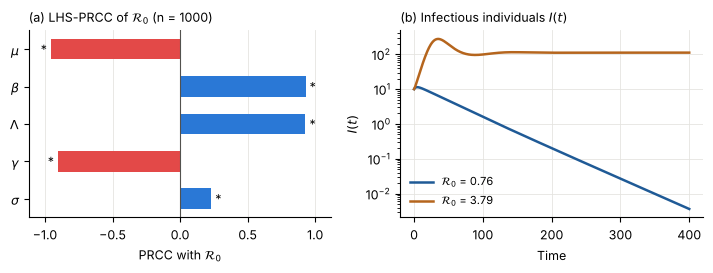

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.8))
prcc.plot(ax=ax[0])
ax[0].set_title("(a) LHS-PRCC of $\\mathcal{R}_0$ (n = 1000)", loc="left", fontsize=9)
baja.plot("I", ax=ax[1], colors=AZUL, labels=f"$\\mathcal{{R}}_0$ = {baja.R0:.2f}", legend=False, logy=True)
alta.plot("I", ax=ax[1], colors=NARANJA, labels=f"$\\mathcal{{R}}_0$ = {alta.R0:.2f}", legend=False, logy=True)
ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title("(b) Infectious individuals $I(t)$", loc="left", fontsize=9)
ax[1].set_xlabel("Time")
ax[1].set_ylabel("$I(t)$")
fig.tight_layout()
fig.savefig("outputs/Figure_2.pdf")           # Figura 2 del artículo
fig.savefig("outputs/Figure_2.png", dpi=300)
plt.show()

## 2. Modelo con linfocitos T colaboradores (Cuesta-Herrera et al., 2025, sistema 2.2)

$$\dot E=\lambda-dE-\kappa EV,\quad \dot I=\kappa EV-\alpha I-\beta T_hI,\quad \dot V=\nu I-\mu V-\tau T_hV,\quad \dot T_h=b-cT_h+\gamma IT_h.$$

Los parámetros son los de la Tabla 1 de la fuente, que informa $\mathcal{R}_0^{*}=6.0303\times10^{3}$ (Fig. 3a). `lambda` es palabra reservada de Python, por eso los valores se dan en un diccionario con claves de texto.

In [9]:
th = R0Model("""
    dE/dt = lambda - d*E - kappa*E*V
    dI/dt = kappa*E*V - alpha*I - beta*Th*I
    dV/dt = nu*I - mu*V - tau*Th*V
    dTh/dt = b - c*Th + gamma*I*Th
""", infected=["I", "V"])
print([bloque["variables"] for bloque in th.dfe_blocks])   # Bloques del equilibrio
display(th.dfe)
th.R0

[['E'], ['Th']]


{E: lambda/d, I: 0, V: 0, Th: b/c}

c**2*kappa*lambda*nu/(d*(alpha*c + b*beta)*(b*tau + c*mu))

In [10]:
print(th.check_assumptions())

van den Driessche & Watmough (2002) assumptions:
  (A1) holds     [symbolic proof for all positive parameters]  non-negative flows
  (A2) holds     [symbolic proof for all positive parameters]  no outflow from an empty compartment
  (A3) holds     [by construction]  no new infections in uninfected compartments
  (A4) holds     [symbolic proof for all positive parameters]  the disease-free subspace is invariant
  (A5) holds     [symbolic proof for all positive parameters]  the DFE is stable without new infections
Theorem 2 applies (R0 is a threshold).


In [11]:
tabla1 = {"lambda": 5e5, "d": 0.1, "kappa": 1e-7, "alpha": 0.1,
          "beta": 1e-7, "nu": 995, "mu": 0.5, "tau": 1e-7,
          "b": 5e4, "c": 0.1, "gamma": 1e-7}  # Tabla 1 de la fuente
print("R0 con la Tabla 1:", th.R0_numeric(tabla1))
display(th.sensitivity_indices())             # Índices locales simbólicos
th.sensitivity_indices(tabla1)                # y en los valores de la Tabla 1

R0 con la Tabla 1: 6030.30303030303


{alpha: -alpha*c/(alpha*c + b*beta),
 b: -b*(alpha*c*tau + 2*b*beta*tau + beta*c*mu)/((alpha*c + b*beta)*(b*tau + c*mu)),
 beta: -b*beta/(alpha*c + b*beta),
 c: b*(alpha*c*tau + 2*b*beta*tau + beta*c*mu)/((alpha*c + b*beta)*(b*tau + c*mu)),
 d: -1,
 kappa: 1,
 lambda: 1,
 mu: -c*mu/(b*tau + c*mu),
 nu: 1,
 tau: -b*tau/(b*tau + c*mu)}

{alpha: -0.6666666666666667,
 b: -0.42424242424242425,
 beta: -0.3333333333333333,
 c: 0.42424242424242425,
 d: -1.0,
 kappa: 1.0,
 lambda: 1.0,
 mu: -0.9090909090909092,
 nu: 1.0,
 tau: -0.09090909090909093}

In [12]:
t0 = time.perf_counter()
sobol = th.sobol_indices(baseline=tabla1, spread=0.2, n=4096, seed=1)   # Sobol, +/-20 %
print(f"{time.perf_counter() - t0:.1f} s; suma de S1 = {sobol.to_dataframe()['S1'].sum():.2f}")
sobol.to_dataframe()

3.5 s; suma de S1 = 0.96


,S1,ST,S1_low,S1_high,ST_low,ST_high,distribution
parameter,,,,,,,
d,0.171107,0.182293,0.153266,0.187764,0.173649,0.191981,"uniform [0.08, 0.12]"
kappa,0.165257,0.176639,0.147919,0.182139,0.167846,0.185839,"uniform [8e-08, 1.2e-07]"
nu,0.163525,0.176389,0.147772,0.183145,0.167687,0.186187,"uniform [796, 1194]"
lambda,0.169098,0.176169,0.151355,0.185089,0.167643,0.185499,"uniform [4e+05, 6e+05]"
mu,0.139938,0.151005,0.125115,0.157223,0.143714,0.158697,"uniform [0.4, 0.6]"
alpha,0.072737,0.082448,0.060581,0.086344,0.078419,0.087006,"uniform [0.08, 0.12]"
c,0.029437,0.033850,0.021506,0.036859,0.031999,0.035633,"uniform [0.08, 0.12]"
b,0.030462,0.033550,0.023140,0.038250,0.031785,0.035452,"uniform [4e+04, 6e+04]"
beta,0.018620,0.020508,0.012543,0.025026,0.019420,0.021637,"uniform [8e-08, 1.2e-07]"


In [13]:
v0 = dict(I=0, V=1e3)                         # Carga viral inicial
baja = th.simulate((0, 200), values=dict(tabla1, kappa=1e-11), initial=v0)   # R0 < 1
alta = th.simulate((0, 200), values=tabla1, initial=v0)                       # R0 > 1
print(f"R0 = {baja.R0:.2f}: V(200) = {baja.final()['V']:.2e}")
print(f"R0 = {alta.R0:.0f}: V(200) = {alta.final()['V']:.2e}, E(200) = {alta.final()['E']:.2e}")

R0 = 0.60: V(200) = 6.94e-03
R0 = 6030: V(200) = 9.24e+08, E(200) = 5.41e+03


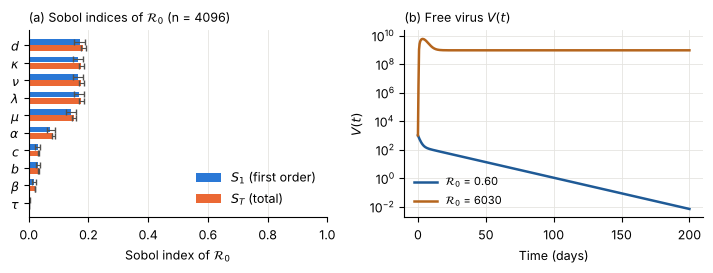

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.8))
sobol.plot(ax=ax[0])
ax[0].set_title("(a) Sobol indices of $\\mathcal{R}_0$ (n = 4096)", loc="left", fontsize=9)
baja.plot("V", ax=ax[1], colors=AZUL, labels=f"$\\mathcal{{R}}_0$ = {baja.R0:.2f}", legend=False, logy=True)
alta.plot("V", ax=ax[1], colors=NARANJA, labels=f"$\\mathcal{{R}}_0$ = {alta.R0:.0f}", legend=False, logy=True)
ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title("(b) Free virus $V(t)$", loc="left", fontsize=9)
ax[1].set_xlabel("Time (days)")
ax[1].set_ylabel("$V(t)$")
fig.tight_layout()
fig.savefig("outputs/Figure_3.pdf")           # Figura 3 del artículo
fig.savefig("outputs/Figure_3.png", dpi=300)
plt.show()